# 04 · Migration fitting and stability

Run the P70 front, model comparison and the full-data plus 18 subsample tests for every classified sequence. Non-migrating and untestable sequences remain visible. The default IC comparison includes the configured step and logarithmic margins; see the parameter documentation.

Migration test: 23 migrations out of 59 sequences.
reason
migration                                 23
N1 jump fits better                       14
N3 stationary fits better                  9
N4 migration fits better but R2 <= 0.5     8
N5 fewer than 10 of 19 runs pass           3
N2 log t expansion fits better             2

Completed migration_test; inputs and products recorded in regional_notebook_session.json.
Classified sequences: 59; analyzed: 59; status rows: 59; individual runs: 1121


,file_name,refined_cluster,sequence_type,status,n_input_events,migration,passing,r2,dic,migration_model,duration,distance,velocity
0,refined_QTM_C11283.0_20091116_M3.6_Direct.csv,0,Mixed,analyzed,85,True,11,0.589366,0.865913,sqrt_ramp,12.870797,0.353849,0.027492
1,refined_QTM_C12359.0_20100109_M2.6_Direct.csv,0,Swarm,analyzed,51,True,11,0.164987,-1.303479,sqrt_ramp,2.644151,0.501657,0.189723
2,refined_QTM_C12438.0_20100112_M4.3_Direct.csv,0,Mixed,analyzed,82,True,11,0.434992,5.284081,sqrt,109.131746,3.310443,0.030334
3,refined_QTM_C13448.0_20100311_M3.5_Direct.csv,0,Mixed,analyzed,251,True,19,0.667564,4.686493,ramp,14.341493,0.502344,0.035027
4,refined_QTM_C13999.0_20100405_M2.8_Direct.csv,0,Swarm,analyzed,56,False,3,0.172867,0.194509,ramp,0.178991,7.357969,41.108101
5,refined_QTM_C15491.0_20100603_M3.2_Direct.csv,0,Swarm,analyzed,59,False,0,0.028684,0.325959,sqrt,91.762297,14.378715,0.156695
6,refined_QTM_C15697.0_20100613_M4.2_Direct.csv,0,MA,analyzed,130,False,0,-0.497854,-4.284727,sqrt_ramp,0.332427,1.226721,3.690195
7,refined_QTM_C15993.0_20100625_M1.4_Direct.csv,0,Swarm,analyzed,50,True,12,0.528741,0.255004,sqrt,1.964636,0.245869,0.125147
8,refined_QTM_C16291.0_20100707_M5.4_Direct.csv,0,MA,analyzed,2191,False,0,-17.067160,-24.115691,sqrt_ramp,0.216522,8.483647,39.181467
9,refined_QTM_C1708.0_20080501_M4.2_Direct.csv,0,Mixed,analyzed,74,False,0,-1.316155,-8.451425,sqrt_ramp,1.273886,6.329989,4.969040


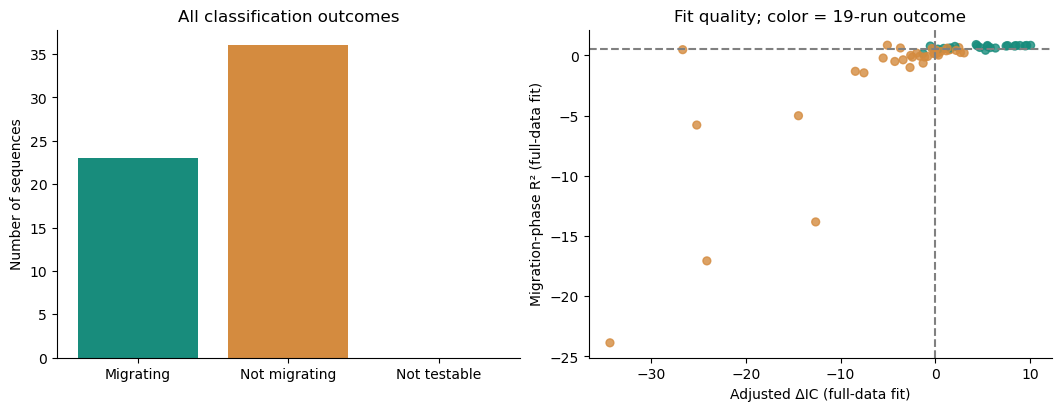

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

here = Path.cwd().resolve()
root = next((p for p in (here, *here.parents) if (p / "run_aspect.py").is_file()), None)
assert root is not None, "Open the notebook from within the ASPECT repository."
sys.path.insert(0, str(root / "notebooks"))
import regional_utils as w
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

w.run_stage("migration_test")
summary = pd.read_csv(w.MIGRATION / "migration_test_summary.csv")
status = pd.read_csv(w.MIGRATION / "migration_test_status.csv")
runs = pd.read_csv(w.MIGRATION / "migration_test_runs.csv.gz")
classes = pd.read_csv(w.TEXT / "classification_results.csv")
print(f"Classified sequences: {len(classes)}; analyzed: {len(summary)}; status rows: {len(status)}; individual runs: {len(runs)}")
assert len(status) == len(classes), "Each classified sequence must have one status row."
assert len(runs) == 19 * len(summary), "Each analyzed sequence must have 19 test runs."
keys = ["file_name", "refined_cluster"]
full = status.merge(summary, on=keys, how="left", suffixes=("", "_summary"), validate="one_to_one")
columns = [c for c in ["file_name", "refined_cluster", "sequence_type", "status", "n_input_events", "migration", "passing", "r2", "dic", "migration_model", "duration", "distance", "velocity"] if c in full.columns]
with pd.option_context("display.max_rows", None, "display.max_colwidth", 100): display(full[columns])
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4), constrained_layout=True)
counts = status.assign(outcome=np.where(status.status.ne("analyzed"), "Not testable", np.where(status.migration.eq(True), "Migrating", "Not migrating"))).outcome.value_counts().reindex(["Migrating", "Not migrating", "Not testable"], fill_value=0)
ax[0].bar(counts.index, counts.values, color=["#188c7c", "#d48b3f", "#a4a7ad"])
ax[0].set(ylabel="Number of sequences", title="All classification outcomes")
ax[0].yaxis.get_major_locator().set_params(integer=True)
ax[1].scatter(summary.dic, summary.r2, c=np.where(summary.migration.eq(True), "#188c7c", "#d48b3f"), s=32, alpha=.8)
ax[1].axvline(w.CFG["migration_test_params"]["dic_threshold"], color=".5", ls="--")
ax[1].axhline(w.CFG["migration_test_params"]["r2"]["threshold"], color=".5", ls="--")
ax[1].set(xlabel="Adjusted ΔIC (full-data fit)", ylabel="Migration-phase R² (full-data fit)", title="Fit quality; color = 19-run outcome")
plt.show()

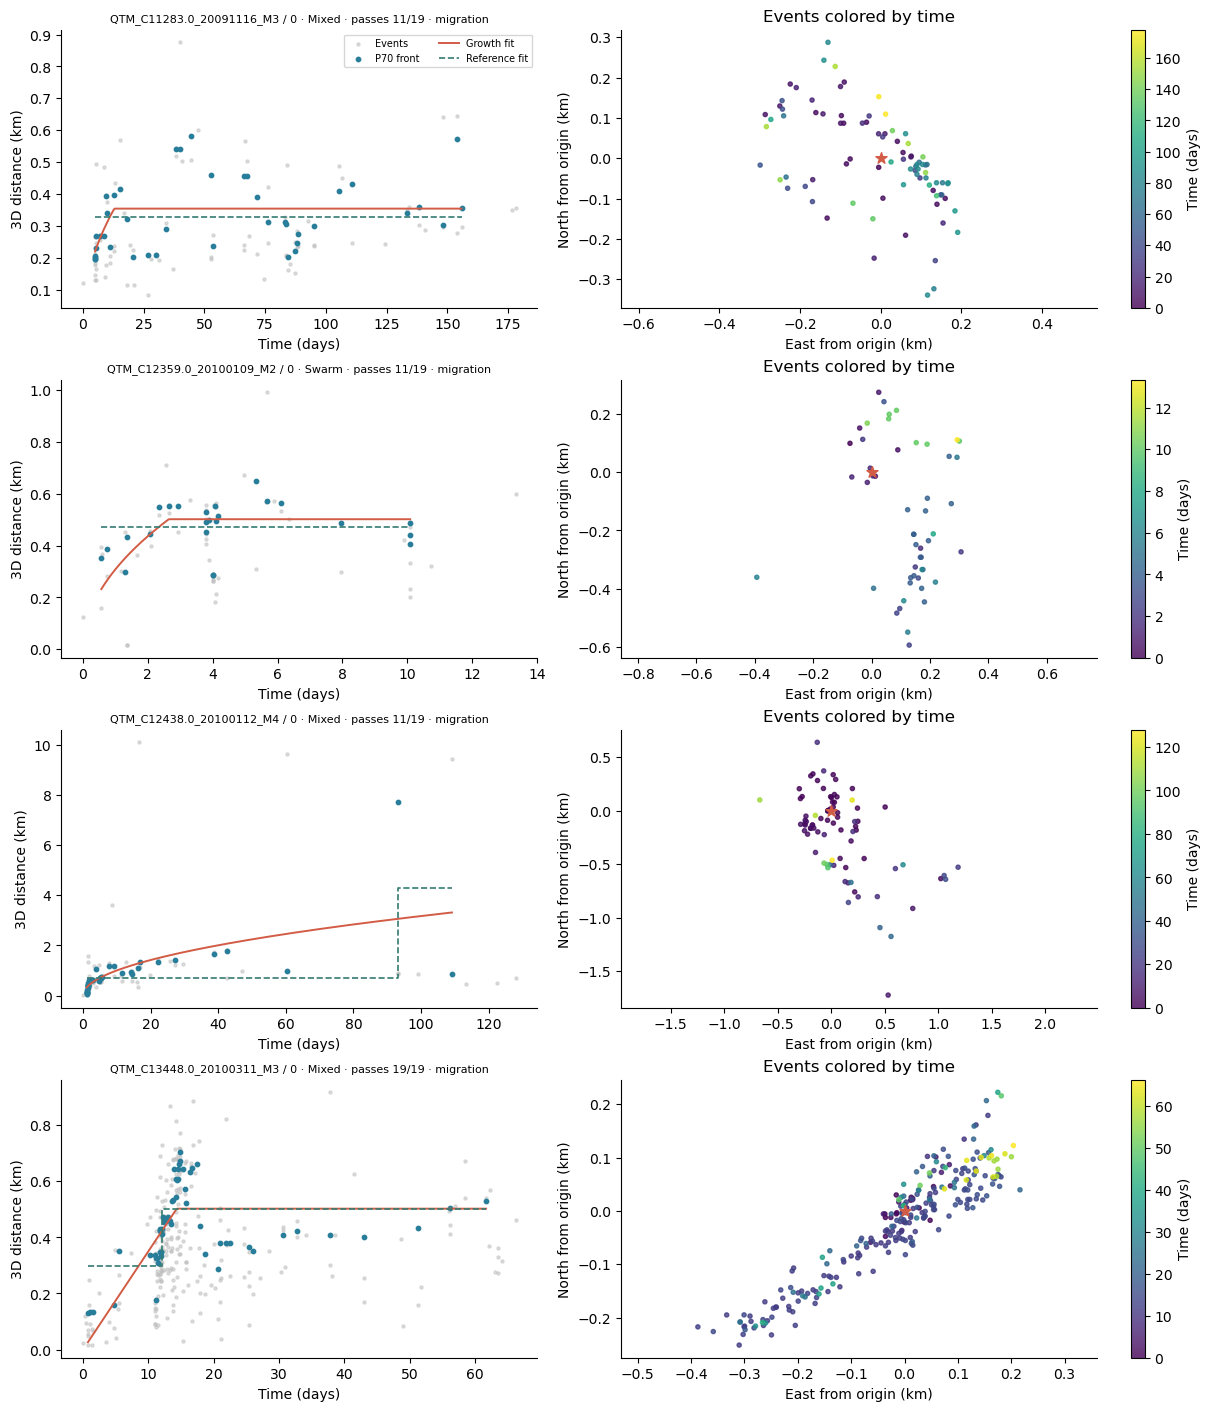

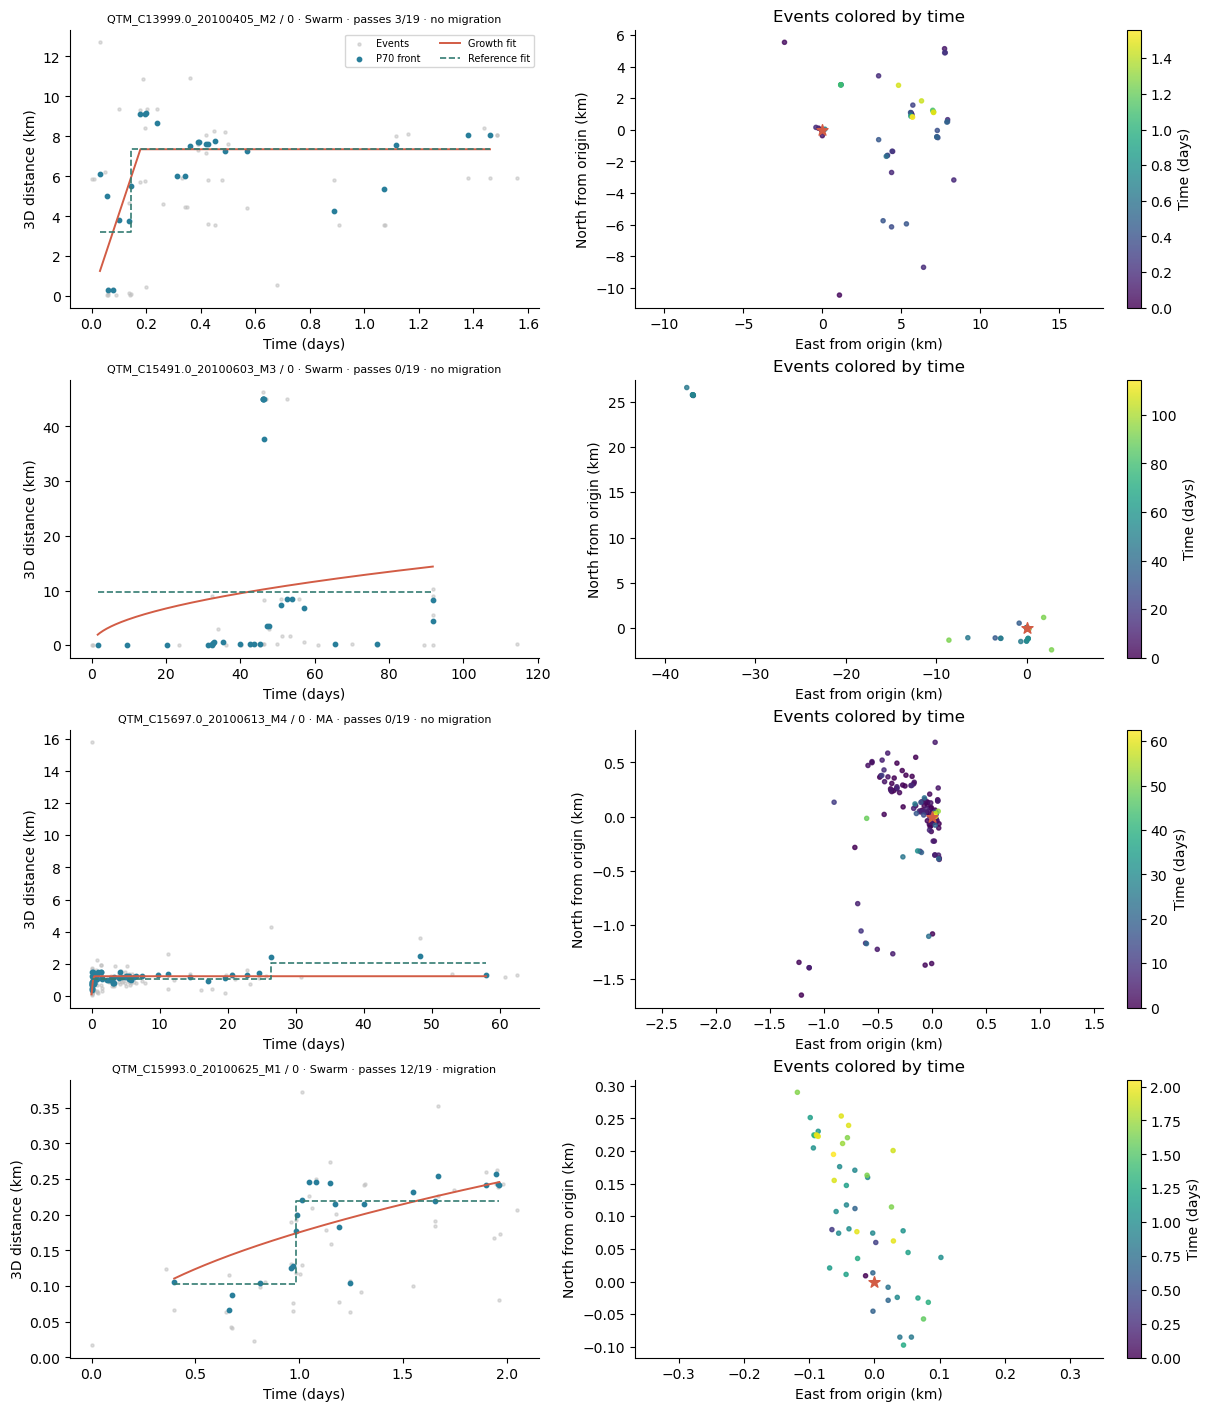

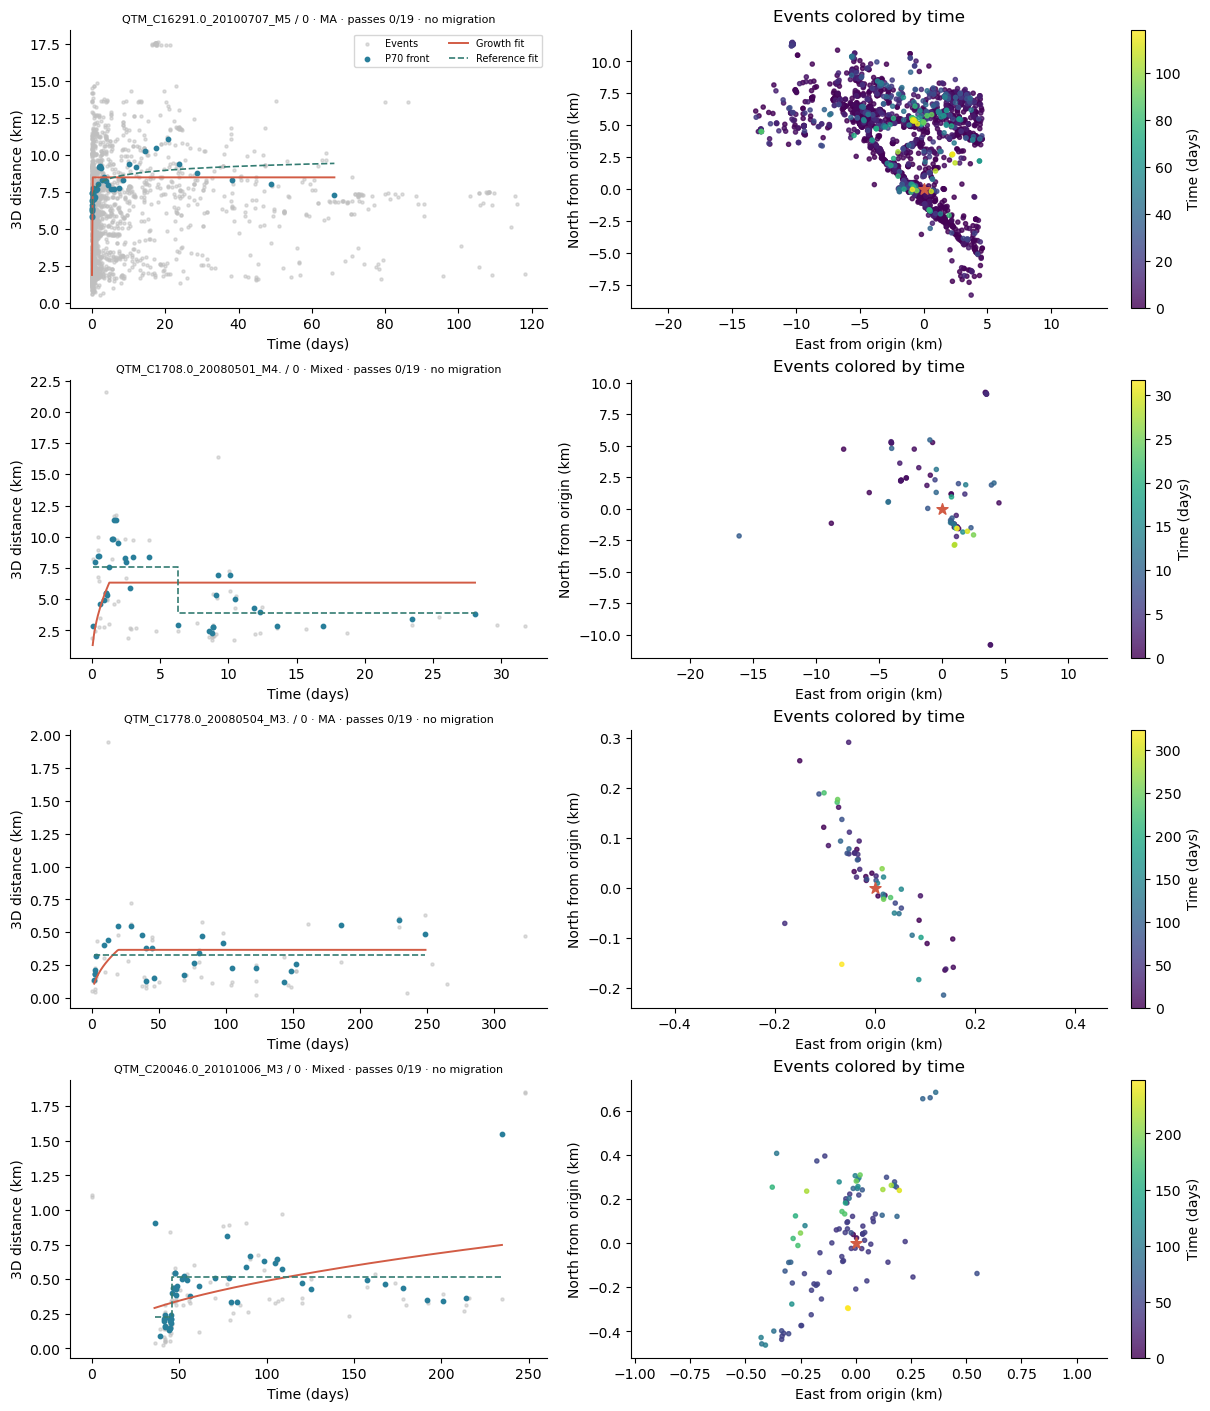

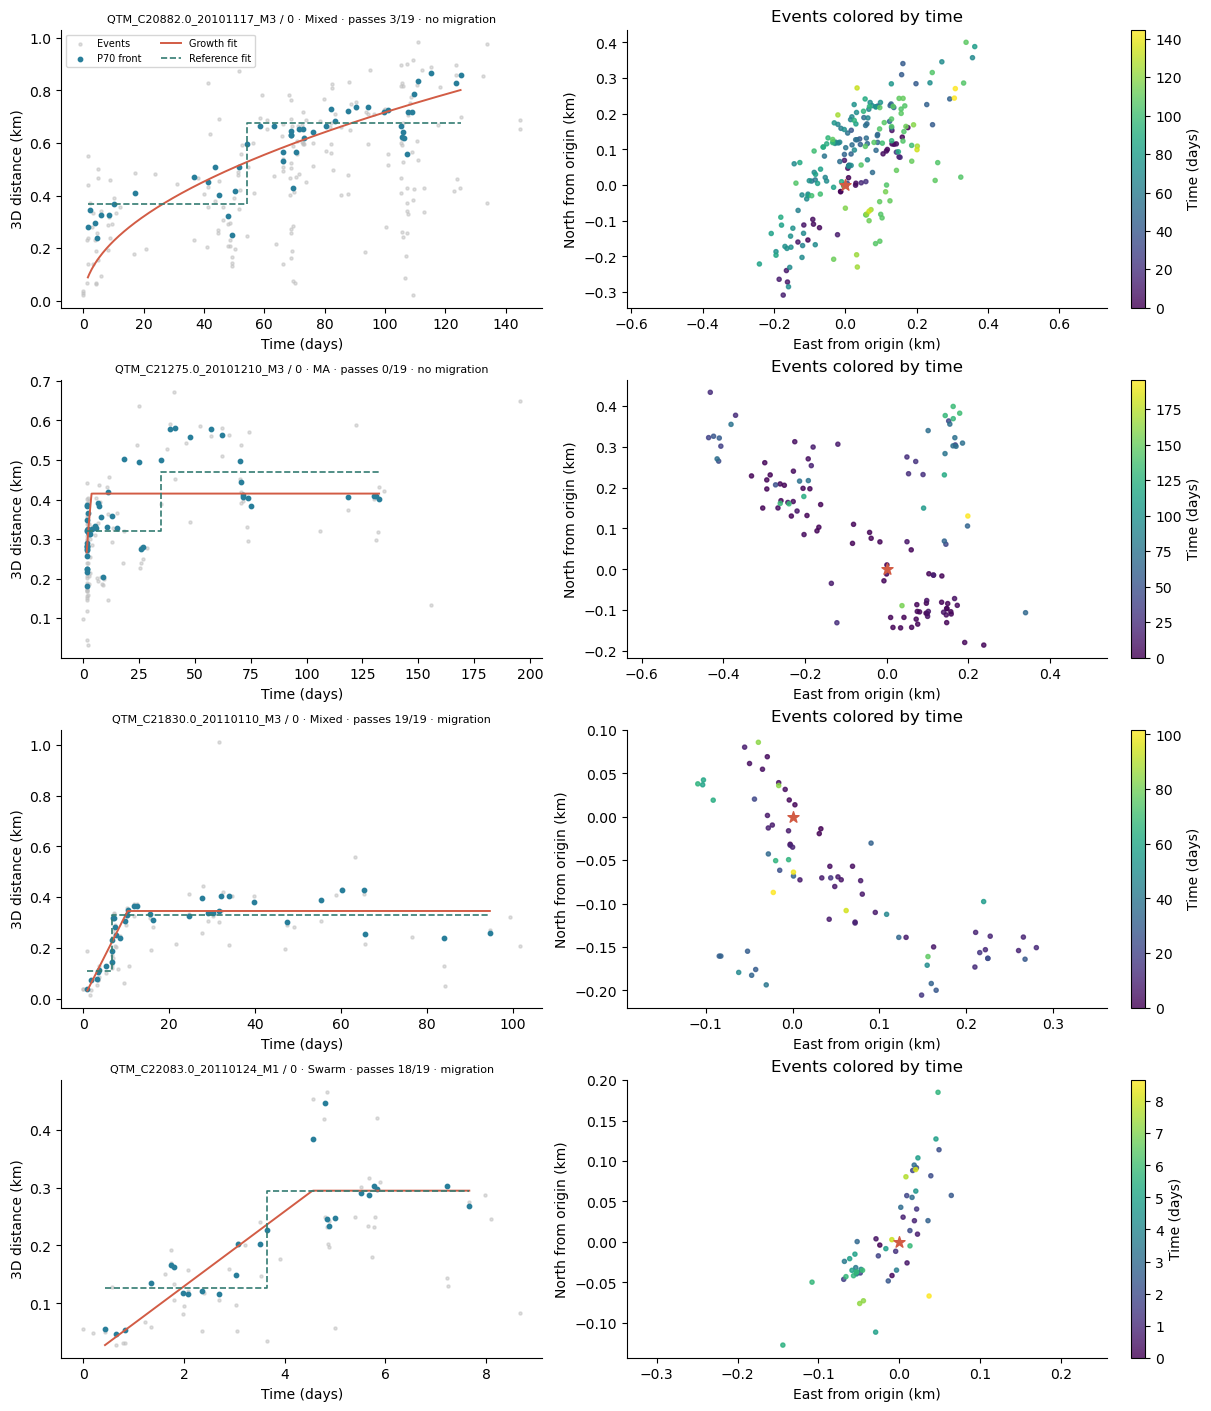

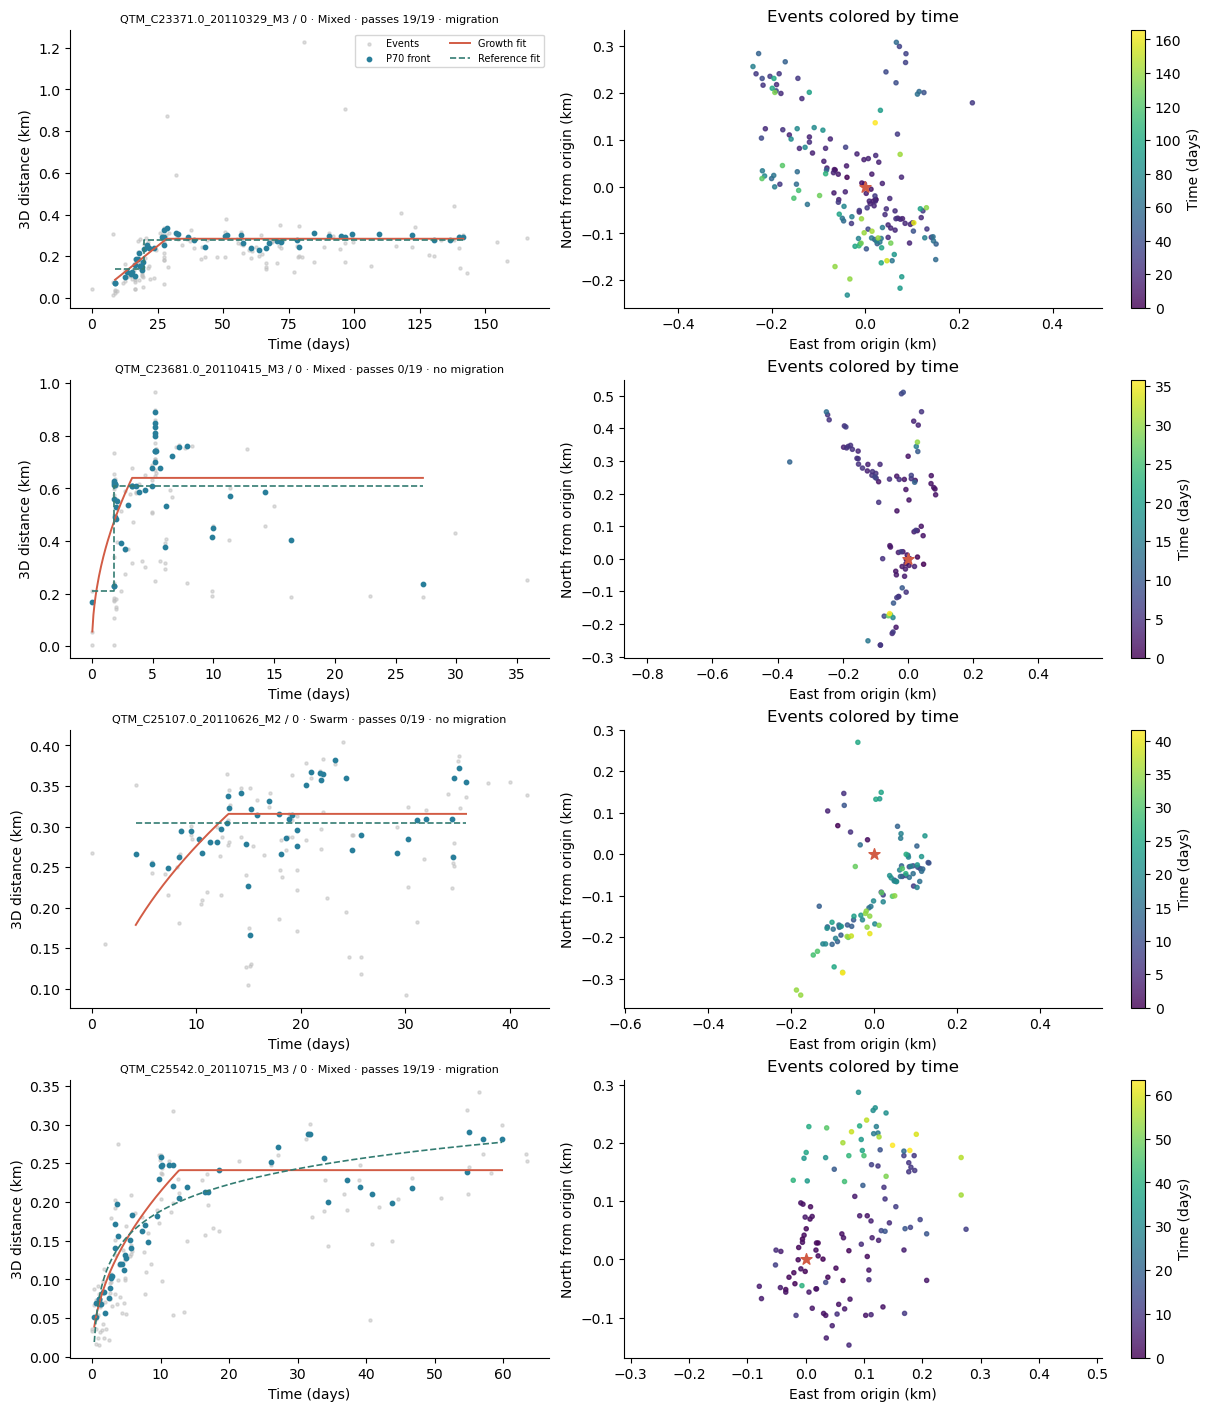

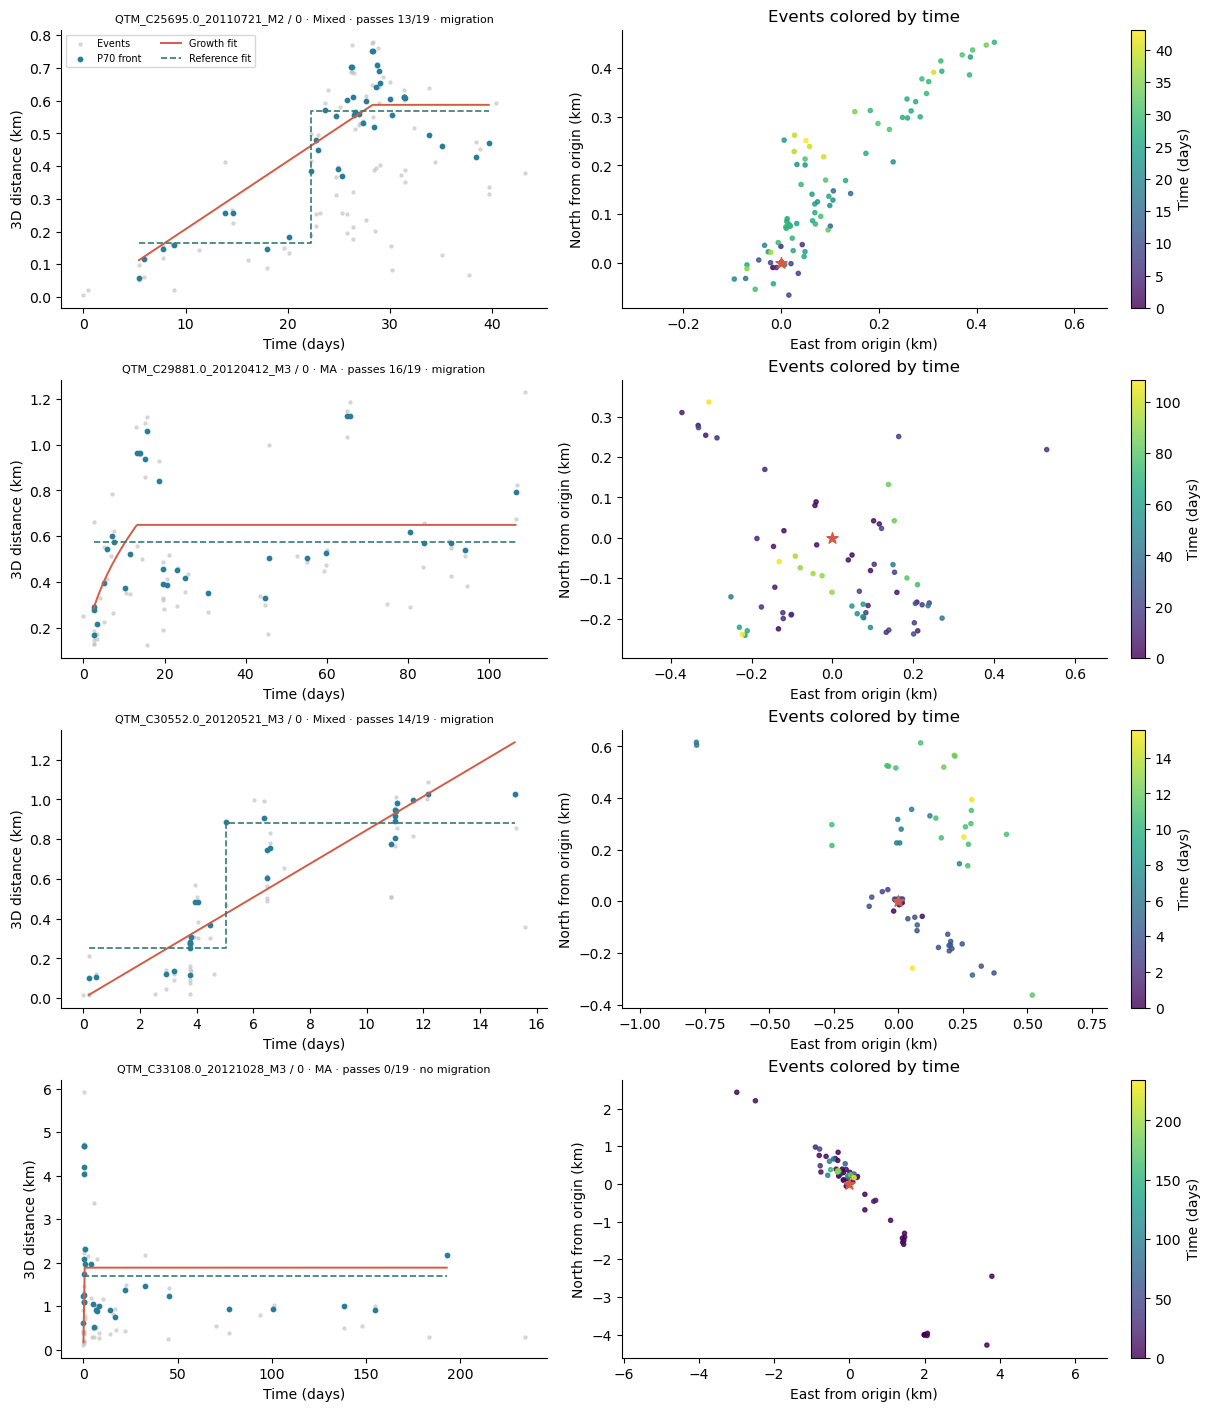

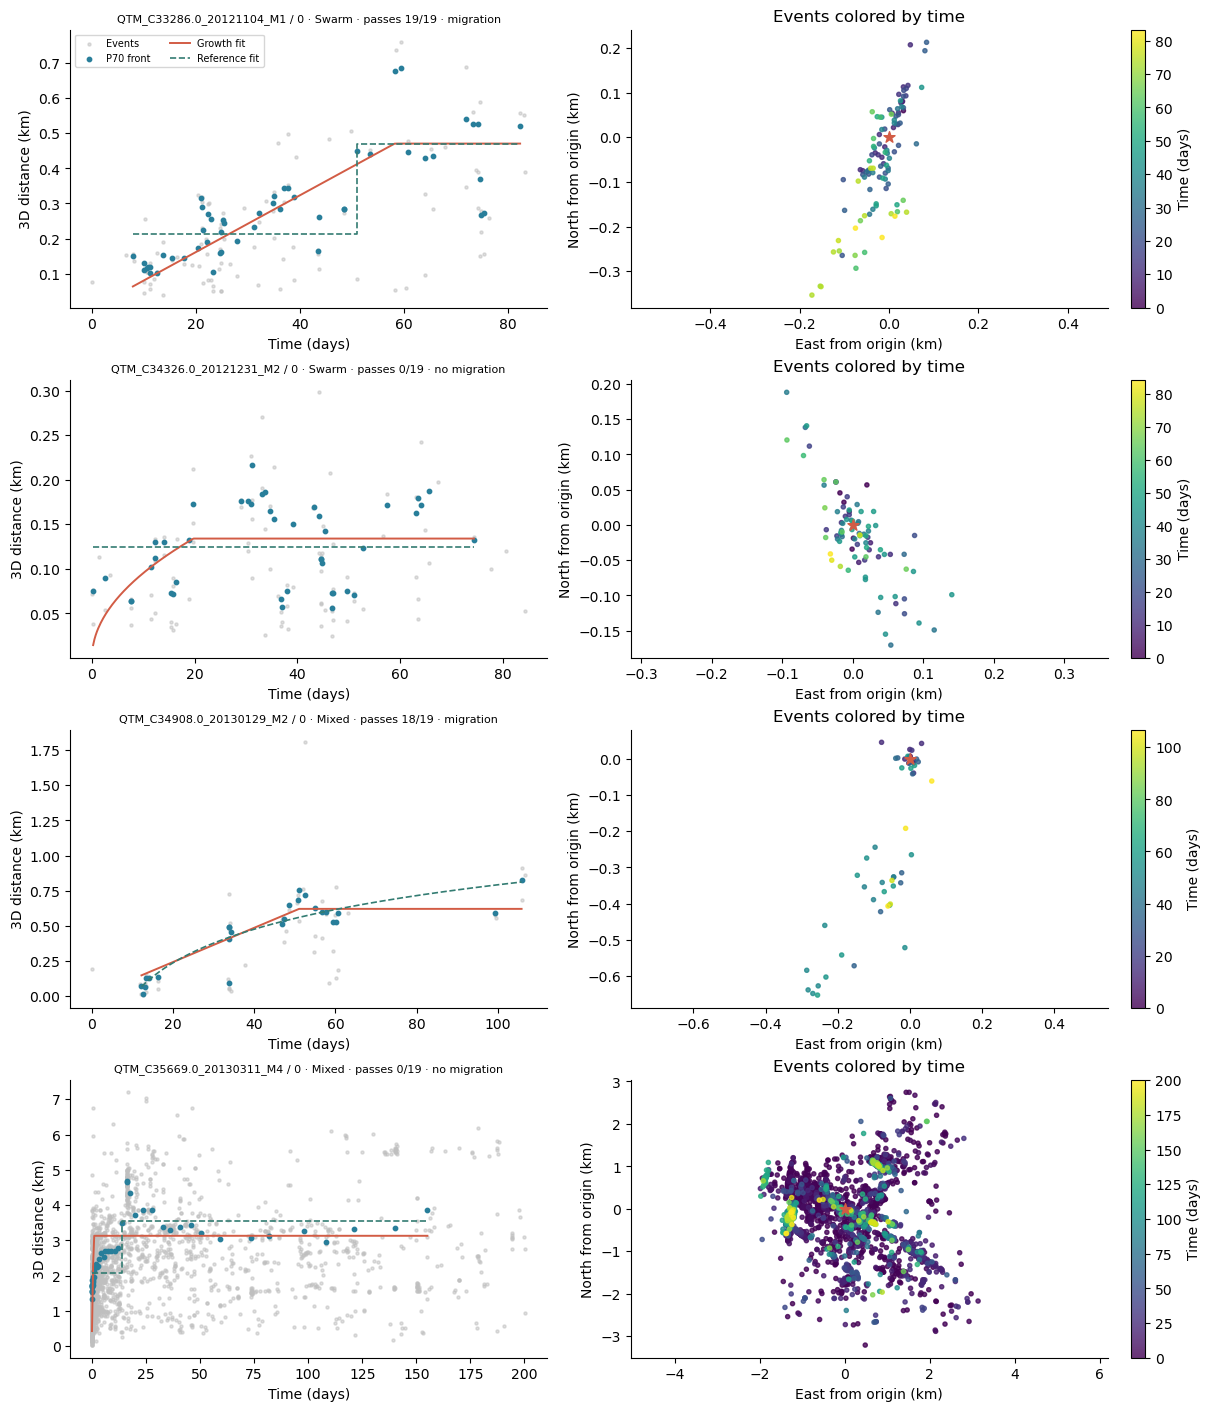

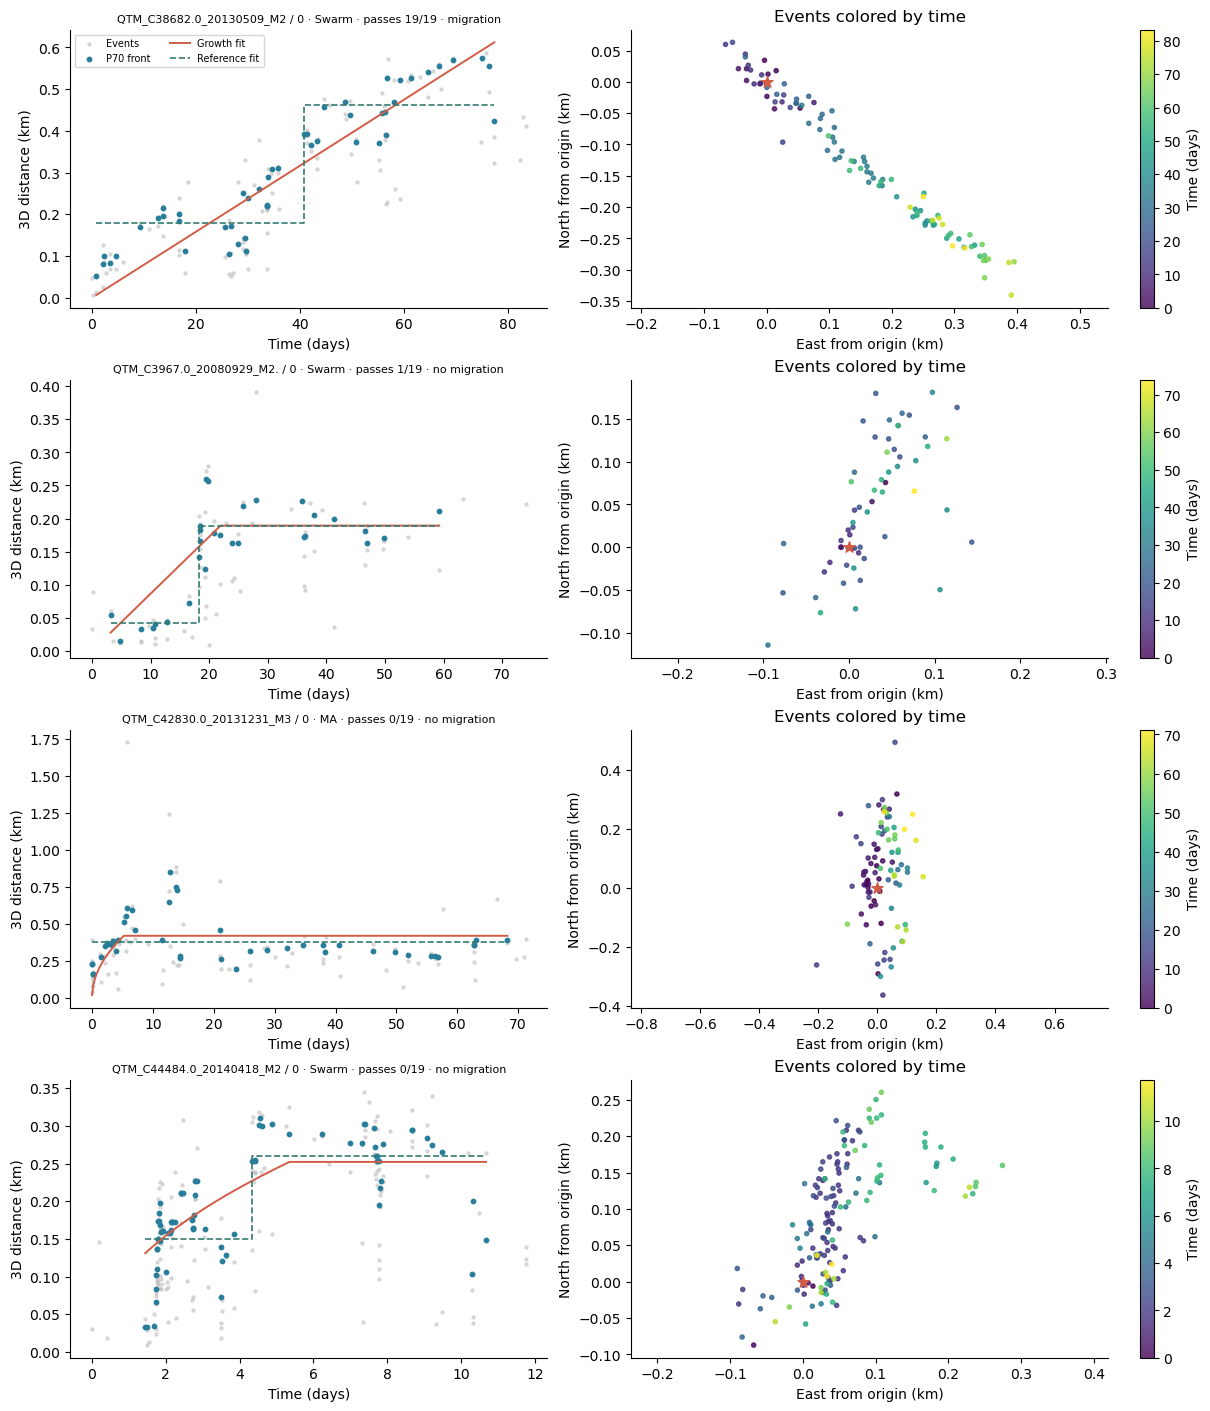

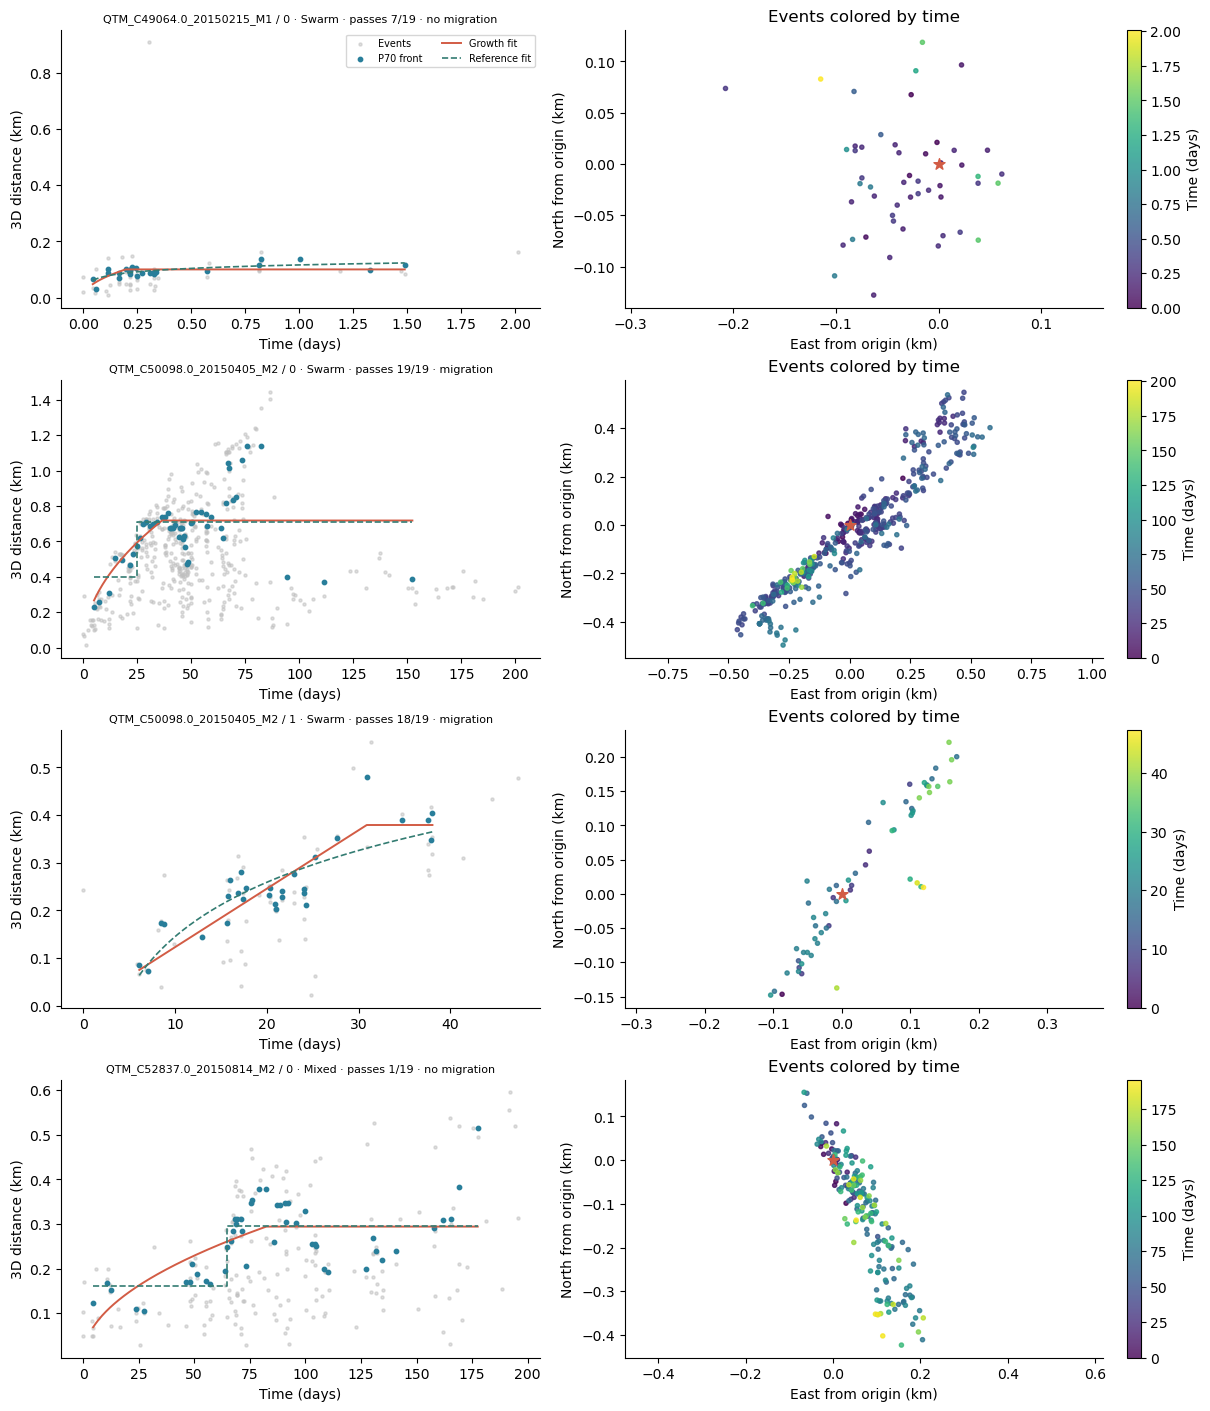

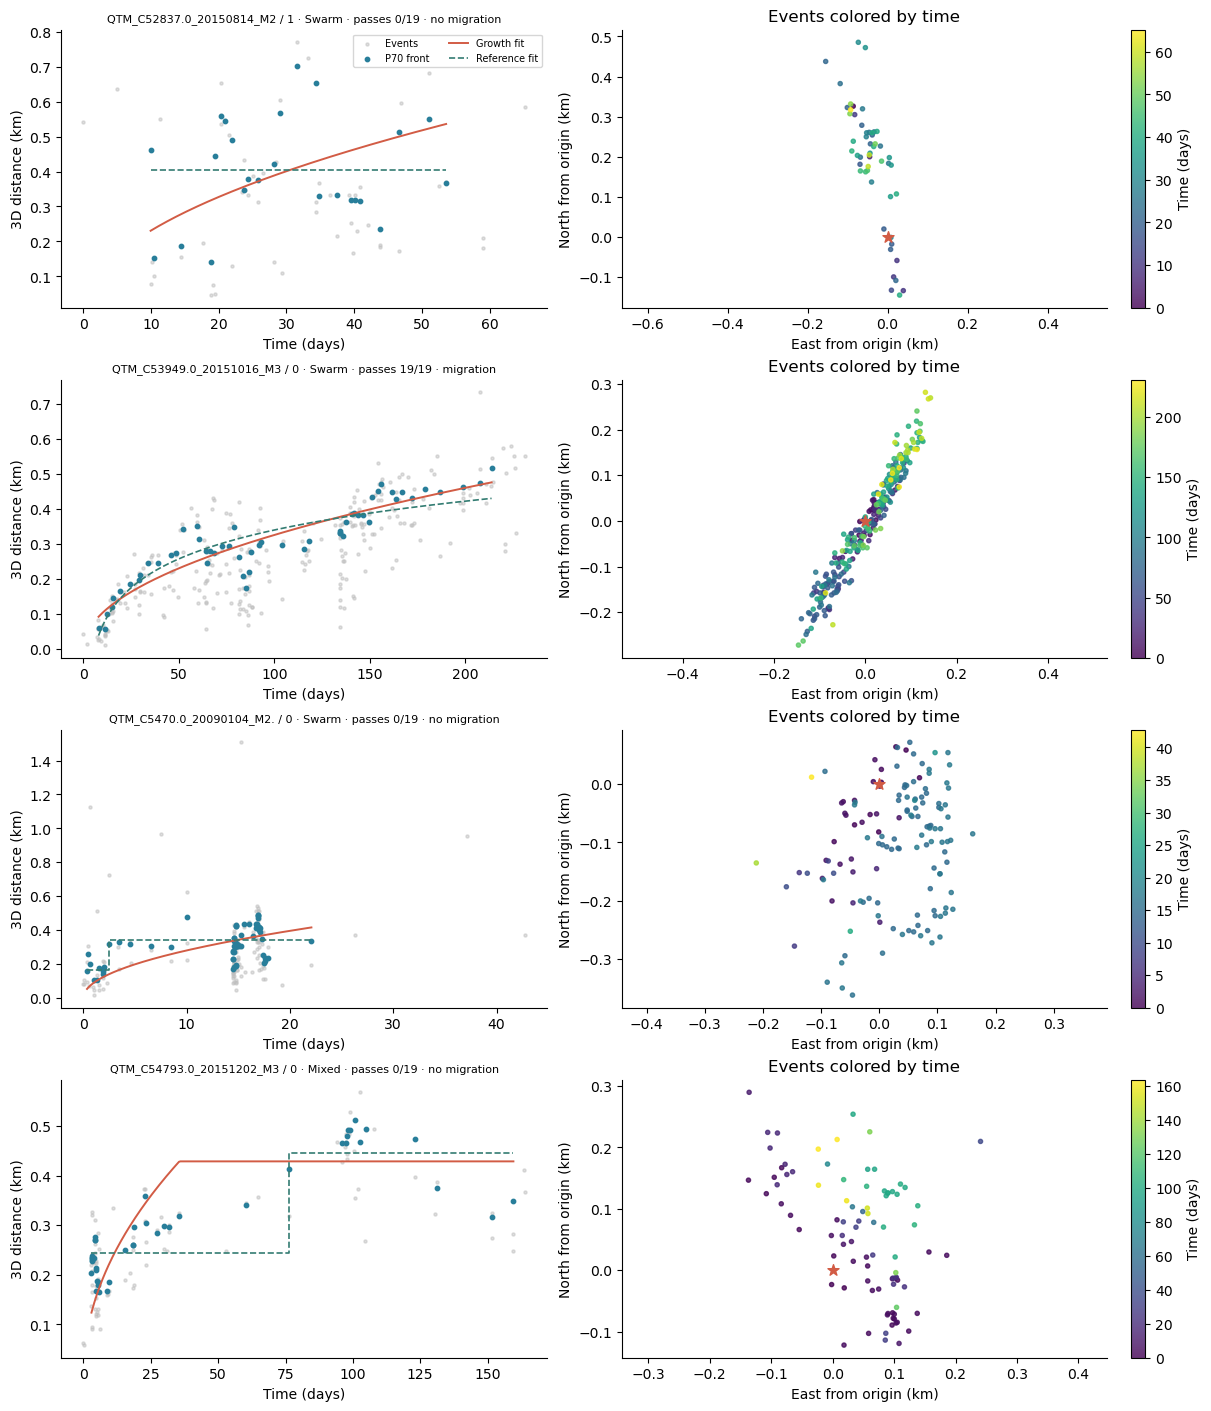

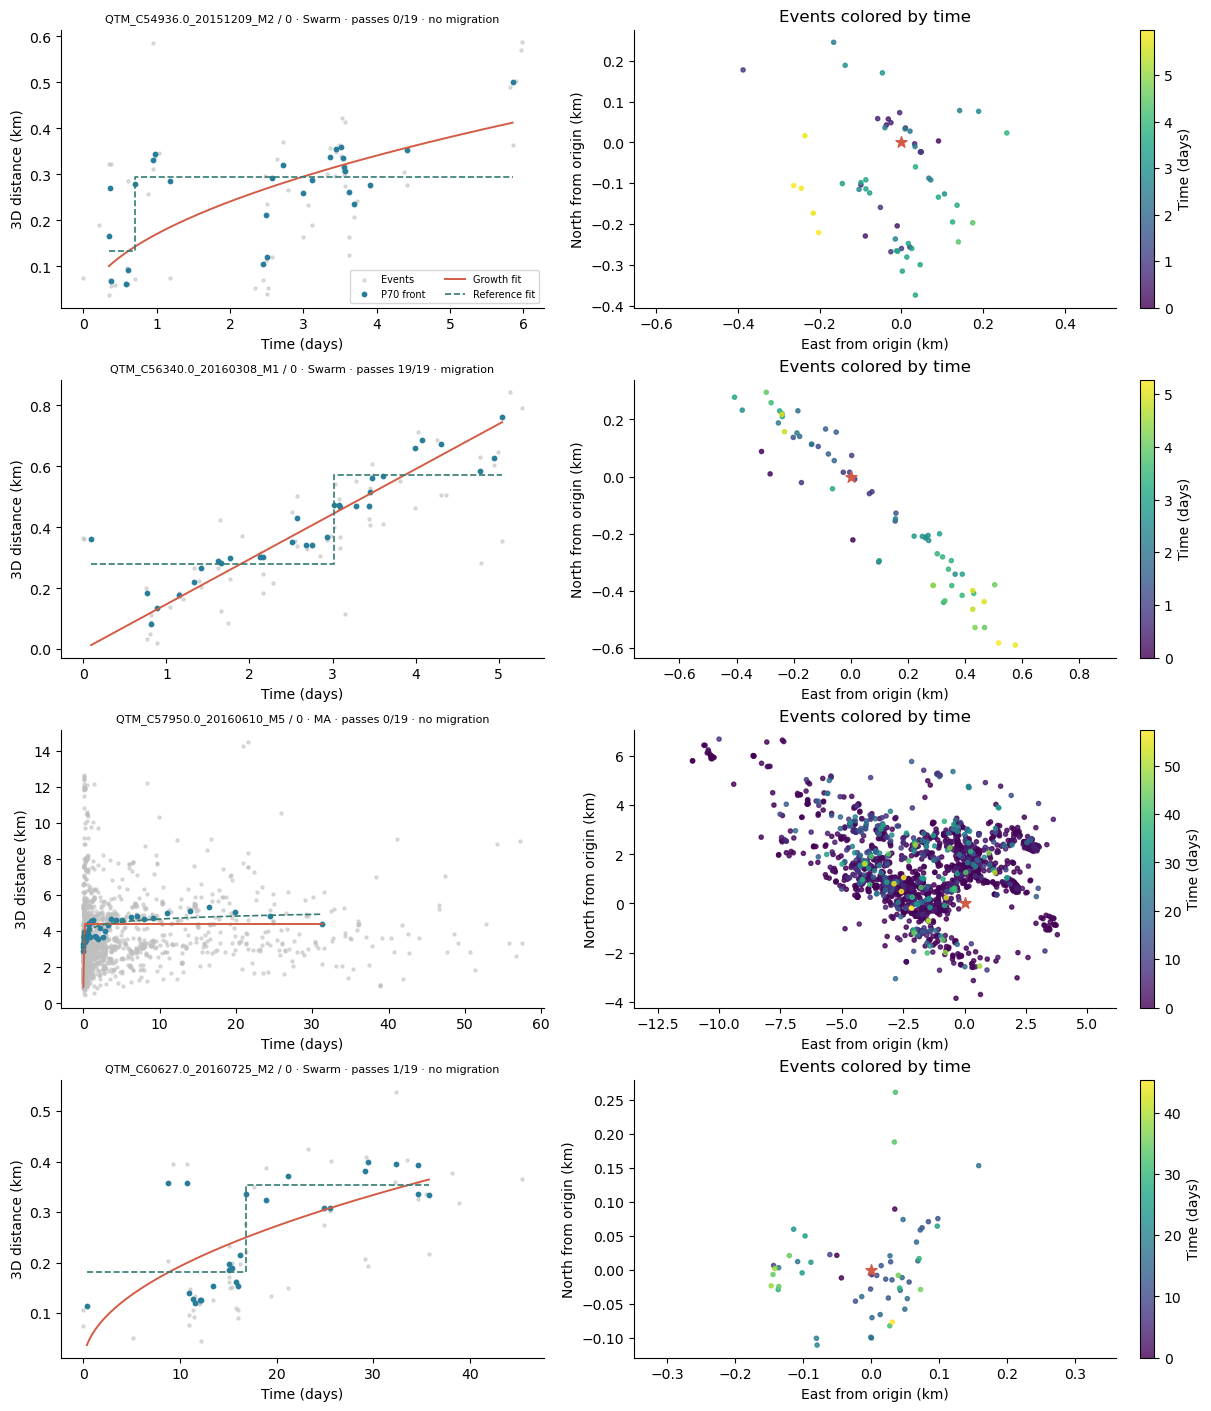

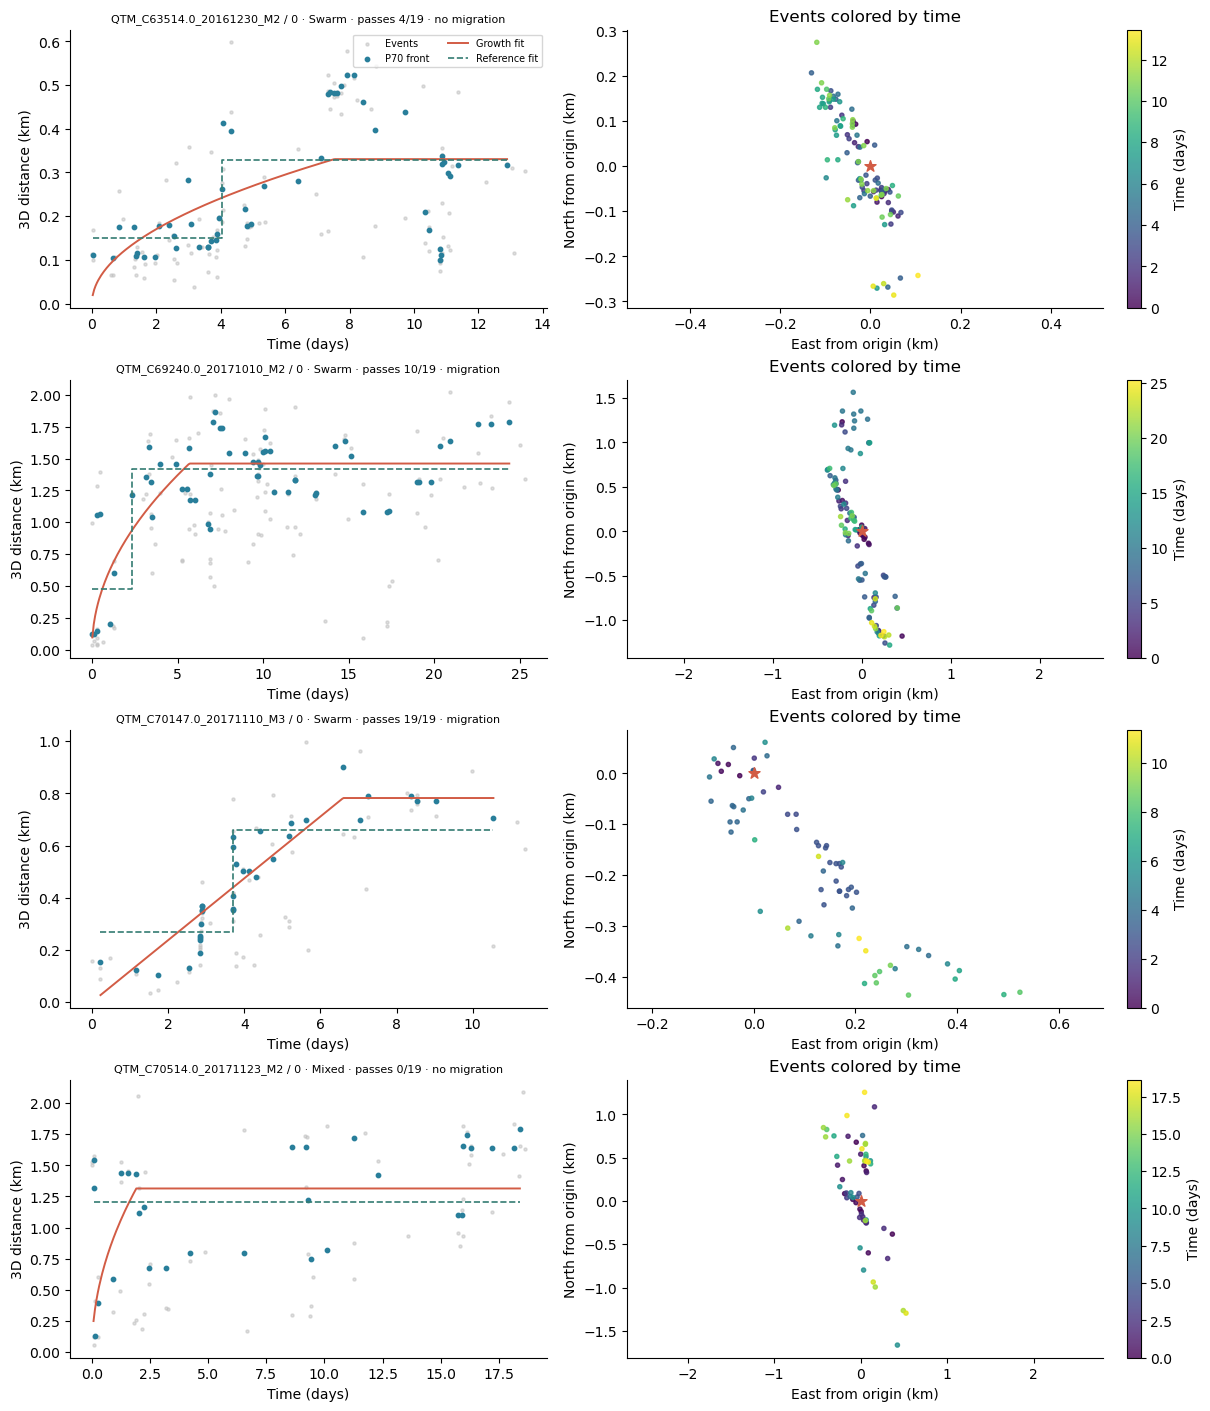

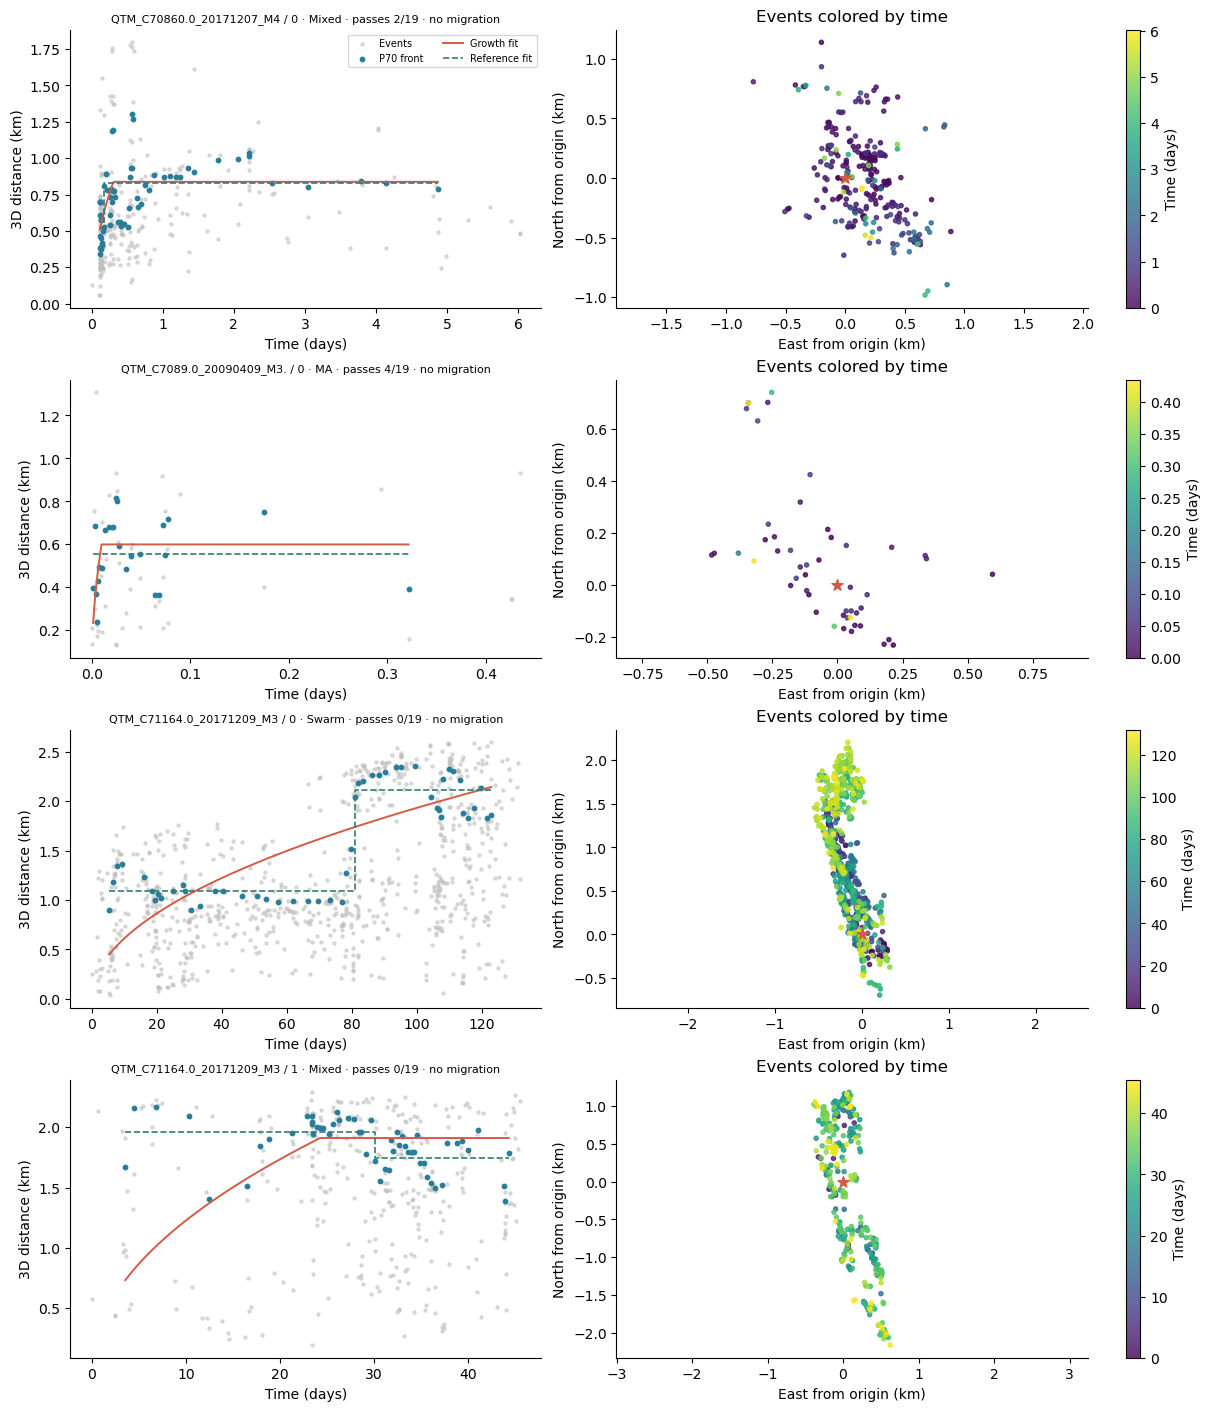

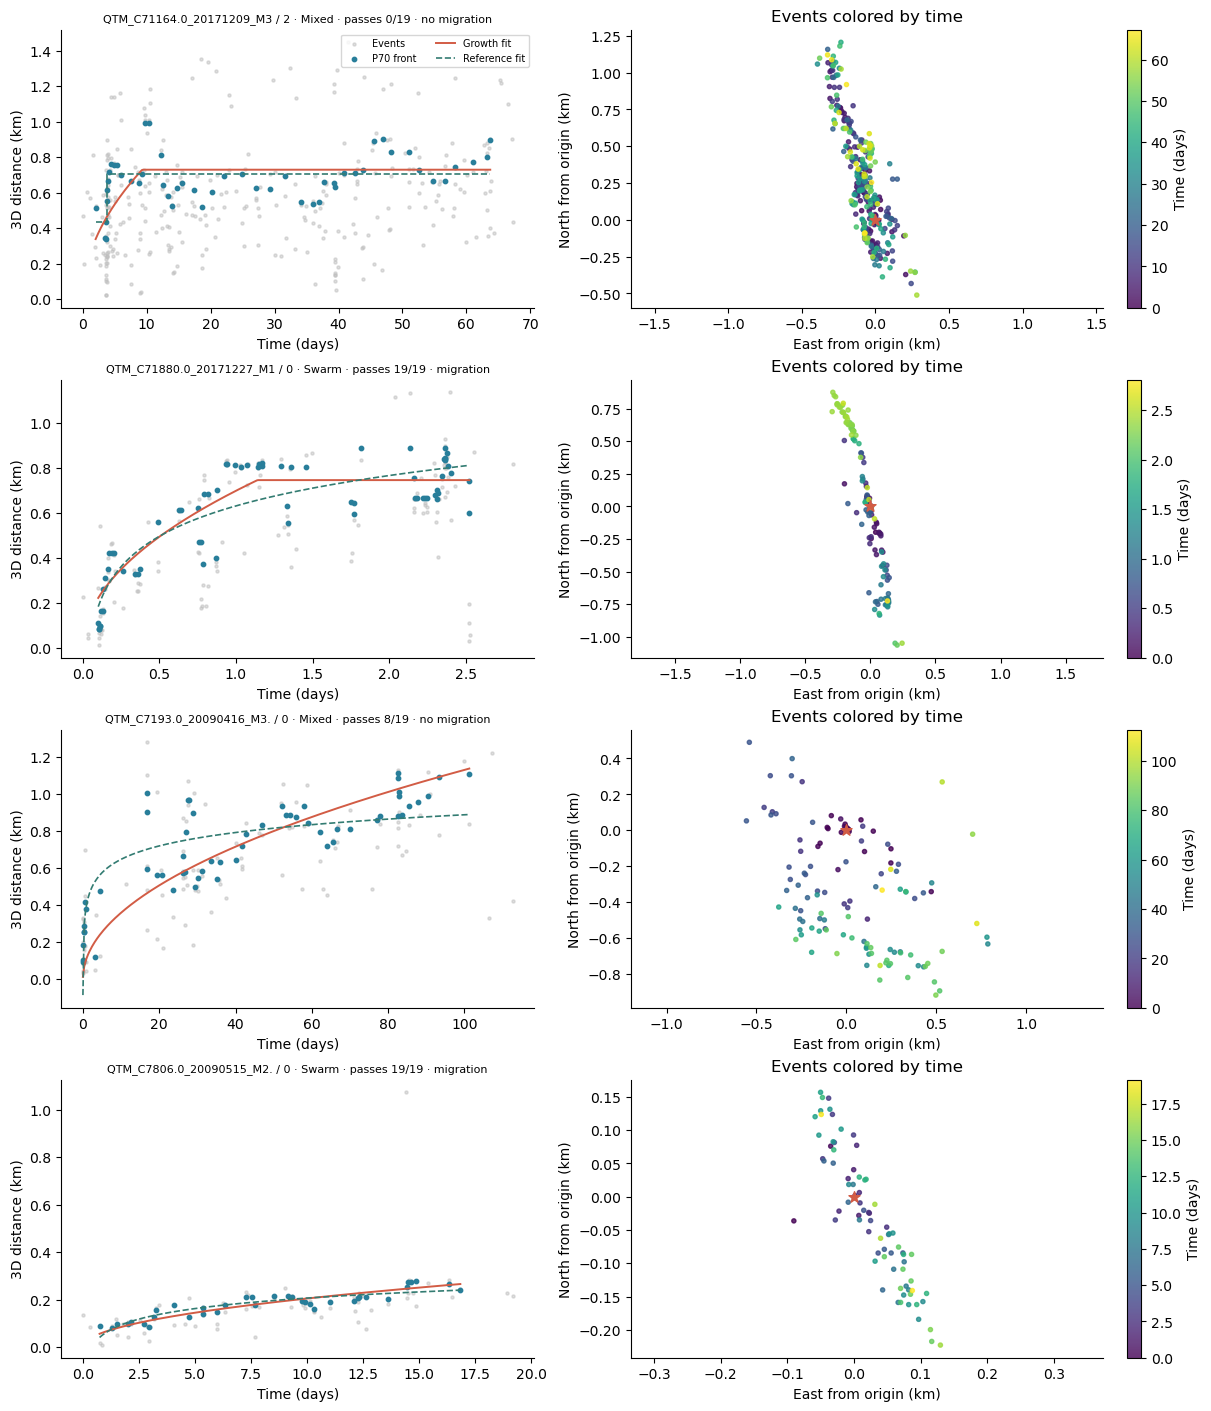

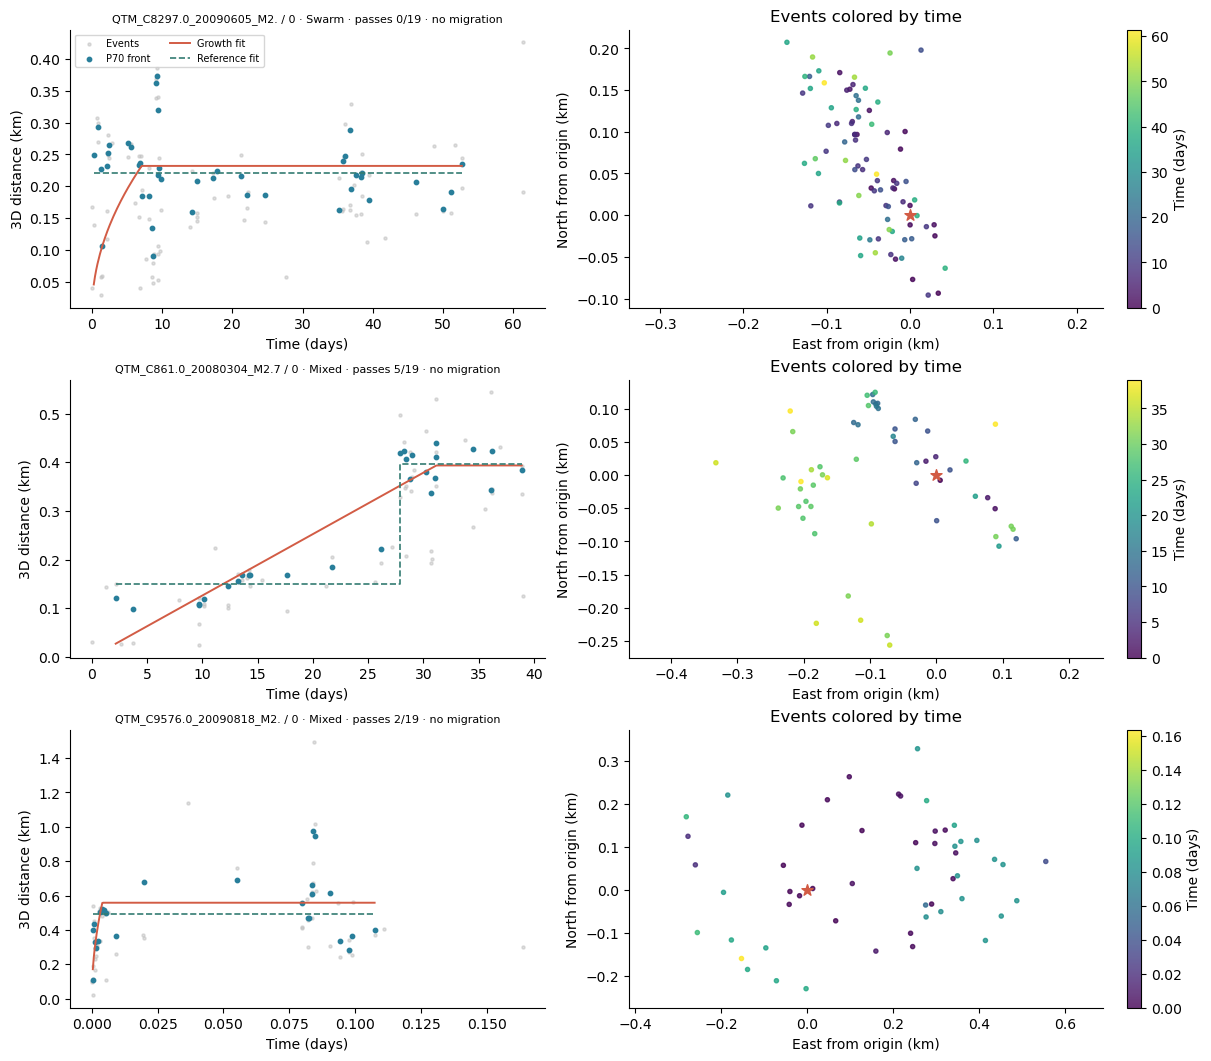

In [2]:
# Display full-data front and best growth/reference fits for every analyzed case.
from aspect.migration_front import trim_early_events, build_front, distance_to_origin
from aspect.migration_models import predict
from aspect.migration_test import MigrationTester

tester = MigrationTester(w.CFG)
for offset in range(0, len(summary), 4):
    page = summary.iloc[offset:offset+4]
    fig, axes = plt.subplots(len(page), 2, figsize=(12, 3.5*len(page)), squeeze=False, constrained_layout=True)
    for axis, (_, row) in zip(axes, page.iterrows()):
        df = pd.read_csv(w.TEXT / row.file_name)
        df = df[df.refined_cluster.eq(row.refined_cluster)].sort_values("stime")
        coords = df[["x", "y", "dep"]].to_numpy(dtype=float)
        time = (df.stime.to_numpy(dtype=float) - df.stime.min()) / 86400
        early = tester.early
        if early.get("enabled", True):
            coords, time, _, _ = trim_early_events(coords, time, lower=early.get("lower_percentile", 10), upper=early.get("upper_percentile", 90), multiplier=early.get("multiplier", 1.0))
        else:
            coords, time, _, _ = trim_early_events(coords, time, min_keep=10**9)
        fraction = tester.params.get("per_run_initial_trim_fraction", 0.0)
        cut = int(np.floor(fraction * len(time)))
        if cut:
            coords, time = coords[cut:], time[cut:]
            time = time - time[0]
        distances, origin = distance_to_origin(coords, tester.n_first)
        ft, fd, _, _ = build_front(coords, time, tester.pct, tester.n_first, tester.window_ratio, tester.step_ratio)
        ax, map_ax = axis
        ax.scatter(time, distances, s=5, color=".75", alpha=.5, label="Events")
        ax.scatter(ft, fd, s=10, color="#287e9a", label=f"P{tester.pct} front")
        fit = tester._one_run(coords, time, tester.pct, tester.n_first)
        if fit["valid"]:
            assert np.isclose(fit["r2"], row.r2, equal_nan=True) and np.isclose(fit["dic"], row.dic, equal_nan=True), "Displayed full-data fit does not match the saved summary."
            models = fit["models"]
            tt = np.linspace(models["_T"].min(), models["_T"].max(), 300)
            best = fit["mig_best"]
            if best:
                ax.plot(tt, predict(best, models[best], tt), color="#d25c45", lw=1.4, label="Growth fit")
            reference = fit["veto"]
            if reference == "const":
                yy = np.full_like(tt, models["_D"].mean())
                ax.plot(tt, yy, color="#337c72", ls="--", lw=1.2, label="Reference fit")
            elif reference == "step":
                model = models[reference]
                ax.plot([tt.min(), model["split"], model["split"], tt.max()], [model["c1"], model["c1"], model["c2"], model["c2"]], color="#337c72", ls="--", lw=1.2, label="Reference fit")
            else:
                ax.plot(tt, predict(reference, models[reference], tt), color="#337c72", ls="--", lw=1.2, label="Reference fit")
        ax.set(xlabel="Time (days)", ylabel="3D distance (km)")
        ax.set_title(f"{row.file_name[8:32]} / {row.refined_cluster} · {row.sequence_type} · passes {int(row.passing)}/19 · {'migration' if row.migration else 'no migration'}", fontsize=8)
        rel = coords[:, :2] - origin[:2]
        sc = map_ax.scatter(rel[:, 0], rel[:, 1], c=time, cmap="viridis", s=9, alpha=.8)
        map_ax.scatter(0, 0, marker="*", color="#d25c45", s=70)
        map_ax.set(xlabel="East from origin (km)", ylabel="North from origin (km)", title="Events colored by time")
        map_ax.set_aspect("equal", adjustable="datalim")
        fig.colorbar(sc, ax=map_ax, label="Time (days)")
    axes[0,0].legend(fontsize=7, ncol=2); plt.show()

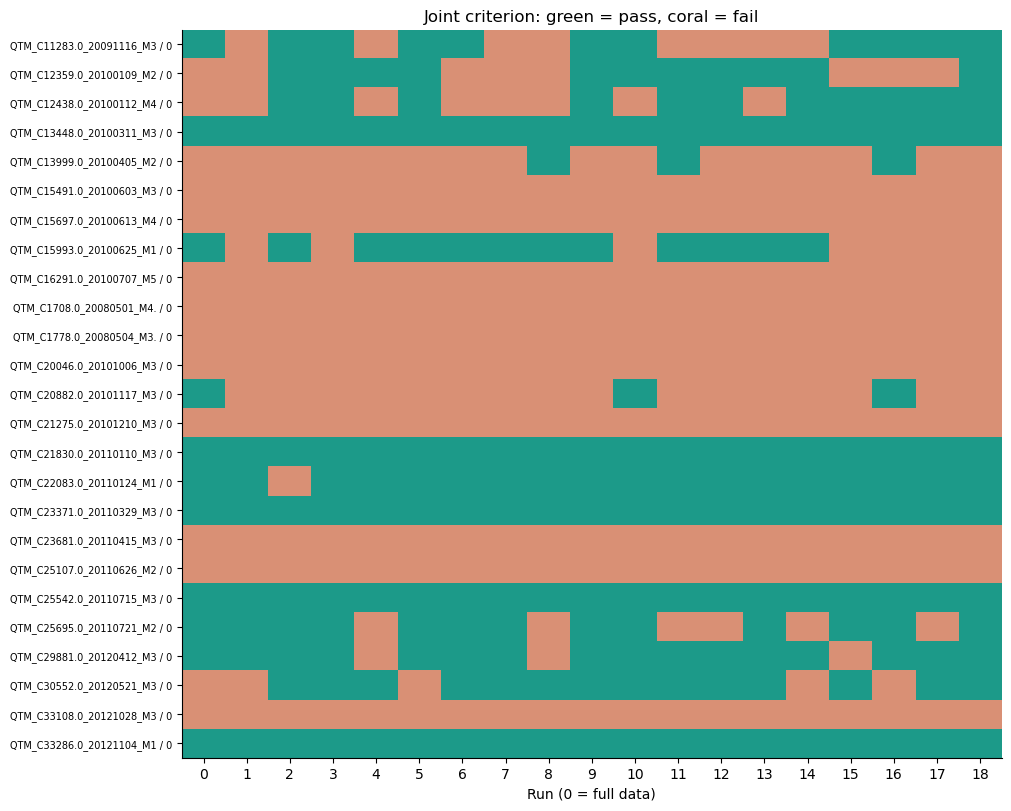

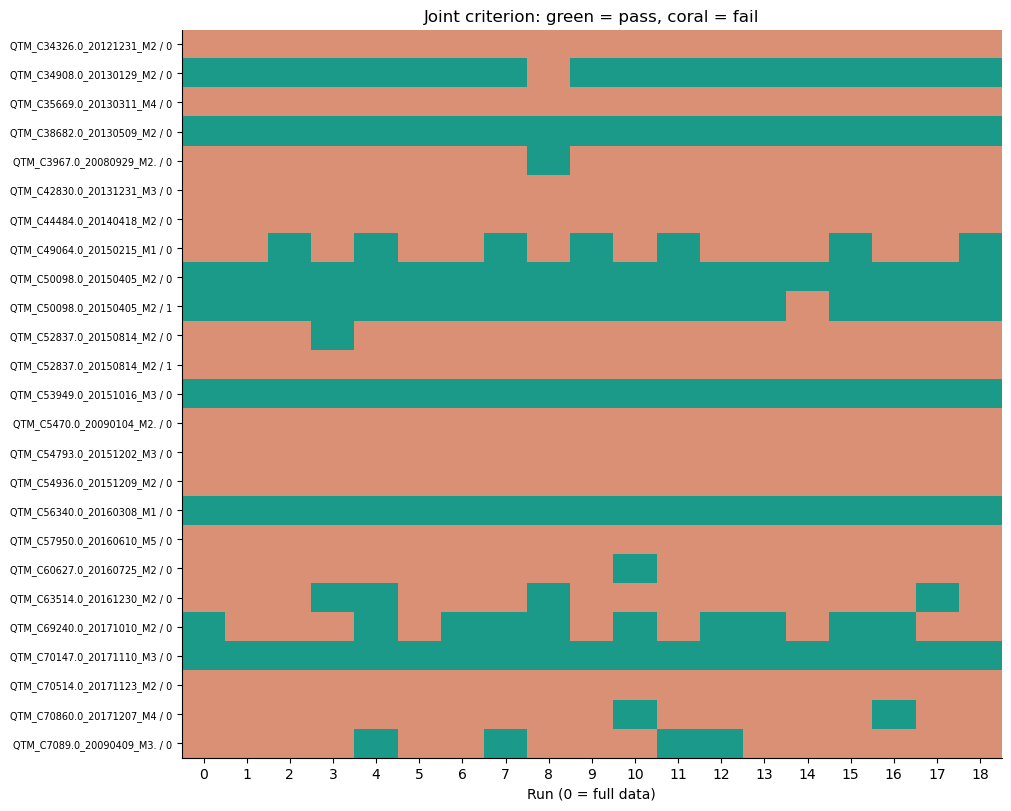

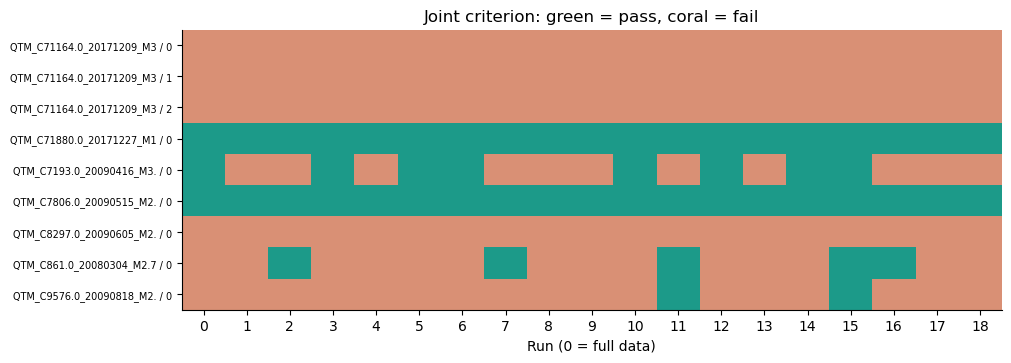

In [3]:
# Show every full-data and subsample joint decision in a paginated matrix.
from matplotlib.colors import ListedColormap
for offset in range(0, len(summary), 25):
    page = summary.iloc[offset:offset + 25]
    rows = []
    labels = []
    for _, row in page.iterrows():
        rr = runs[(runs.file_name == row.file_name) & (runs.refined_cluster == row.refined_cluster)].sort_values("version")
        assert len(rr) == 19 and list(rr.version) == list(range(19))
        rows.append(rr.joint_pass.astype(int).to_numpy())
        labels.append(f"{row.file_name[8:32]} / {row.refined_cluster}")
    fig, ax = plt.subplots(figsize=(10, max(3, .28*len(rows)+1)), constrained_layout=True)
    im = ax.imshow(rows, aspect="auto", interpolation="nearest", cmap=ListedColormap(["#d99075", "#1c9a89"]), vmin=0, vmax=1)
    ax.set(xticks=np.arange(19), yticks=np.arange(len(labels)), yticklabels=labels, xlabel="Run (0 = full data)", title="Joint criterion: green = pass, coral = fail")
    ax.tick_params(axis="y", labelsize=7)
    plt.show()

In [4]:
# Report all sequences that could not be tested after preprocessing.
untestable = status[status.status.ne("analyzed")]
print(f"Untestable sequences: {len(untestable)}")
with pd.option_context("display.max_rows", None, "display.max_colwidth", 100): display(untestable)

Untestable sequences: 0


,file_name,refined_cluster,sequence_type,seed,status,n_input_events,n_events,migration


Every analyzed case appears in the table, in a full-data front/map panel, and in a 19-run joint-decision matrix. Untestable cases are listed separately. A migration classification is an empirical result and does not by itself identify a slow-slip or fluid-driven mechanism.